## Dataset columns

| Column | Meaning | Use |
|---|---|---|
| `person_age` | Applicant age | Numeric predictor |
| `person_income` | Annual income in dollars | Numeric predictor |
| `person_home_ownership` | RENT, OWN, MORTGAGE, etc. | Categorical predictor |
| `person_emp_length` | Employment length in years | Numeric predictor |
| `loan_intent` | Intended loan purpose | Categorical predictor |
| `loan_grade` | Loan risk grade | Categorical predictor (full-information model only) |
| `loan_amnt` | Requested loan amount | Numeric predictor |
| `loan_int_rate` | Loan interest rate | Numeric predictor (full-information model only) |
| **`loan_status`** | Recorded outcome: 0 or 1 | **Target to predict** |
| `loan_percent_income` | Loan amount relative to annual income | Numeric predictor |
| `cb_person_default_on_file` | Previous default: Y/N | Categorical predictor |
| `cb_person_cred_hist_length` | Years of credit history | Numeric predictor |

**Two prediction setups:** The **full-information** model uses all 11 predictors. The **early-application** model uses 9 and excludes `loan_grade` and `loan_int_rate`, because those may not exist until after a loan is assessed. We will compare their performance.

## 1. Import the libraries

You can run this in Jupyter Notebook or Google Colab. Most Colab environments already contain these libraries. In another environment, install them with `pip install pandas numpy matplotlib seaborn scikit-learn joblib`.

In [1]:
import zipfile
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("Ready to load the dataset.")

Ready to load the dataset.


## 2. Load the original CSV or ZIP

Place `Loan Approval Prediction Dataset-2.zip` (or its CSV file) in the same directory as this notebook. In **Google Colab**, upload the file using the folder icon on the left. The code tries ZIP files first and checks the CSV columns before accepting the data. No example or simulated data is silently substituted.

In [2]:
expected_columns = [
    "person_age", "person_income", "person_home_ownership",
    "person_emp_length", "loan_intent", "loan_grade", "loan_amnt",
    "loan_int_rate", "loan_status", "loan_percent_income",
    "cb_person_default_on_file", "cb_person_cred_hist_length"
]

folder = Path.cwd()
zip_files = sorted(folder.glob("*.zip"))
csv_files = sorted(folder.glob("*.csv"))

df = None
loaded_from = None

# Read CSV candidates inside ZIP files without extracting them.
for zip_path in zip_files:
    with zipfile.ZipFile(zip_path, "r") as z:
        names = [name for name in z.namelist()
                 if name.lower().endswith(".csv") and not name.startswith("__MACOSX/")]
        for name in names:
            with z.open(name) as f:
                candidate = pd.read_csv(f)
            candidate.columns = candidate.columns.str.strip()
            if set(expected_columns).issubset(candidate.columns):
                df = candidate
                loaded_from = f"{zip_path.name} -> {name}"
                break
    if df is not None:
        break

# If there is no suitable ZIP, read an ordinary CSV.
if df is None:
    for csv_path in csv_files:
        candidate = pd.read_csv(csv_path)
        candidate.columns = candidate.columns.str.strip()
        if set(expected_columns).issubset(candidate.columns):
            df = candidate
            loaded_from = csv_path.name
            break

if df is None:
    raise FileNotFoundError(
        "Could not find a ZIP/CSV containing all 12 expected columns. "
        "Upload your dataset into the notebook folder and rerun this cell."
    )

# Keep only the 12 fields specified for this project, in the correct order.
df = df[expected_columns].copy()
print("Loaded:", loaded_from)
print("Dataset shape:", df.shape)
display(df.head())

Loaded: credit_risk_dataset.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 3. Check data types, missing values, and duplicates

The dataset description reports missing values in `person_emp_length` and `loan_int_rate`. The next cells calculate the **actual** counts in your file. We do not fill missing values yet because doing that before the train/test split can cause data leakage.

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn types:")
print(df.dtypes)

print("\nFirst five rows:")
display(df.head())

print("\nNumerical summary:")
display(df.describe().round(2))

print("\nCategorical summary:")
display(df.describe(include="object"))

Rows: 32581
Columns: 12

Column types:
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

First five rows:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



Numerical summary:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00



Categorical summary:


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


In [4]:
missing_values = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing values", ascending=False)

display(missing_values)
print("Exact duplicate rows:", df.duplicated().sum())

# Remove exact duplicates so the same record cannot end up in both splits.
df = df.drop_duplicates().copy()
print("Rows remaining after duplicate removal:", len(df))

,Missing values,Missing percentage
loan_int_rate,3116,9.56
person_emp_length,895,2.75
person_income,0,0.00
person_age,0,0.00
person_home_ownership,0,0.00
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_status,0,0.00
loan_percent_income,0,0.00


Exact duplicate rows: 165
Rows remaining after duplicate removal: 32416


## 4. Identify the target column

The code prepares `loan_status` as a binary classification target. When it contains numeric `0` and `1`, we keep the labels unchanged and do **not** guess which is approval or default. If the column contains text, we display its coding. Confirm the meaning of the labels using the original dataset description.

In [5]:
# Make sure numeric predictors are actually numerical.
numeric_columns = [
    "person_age", "person_income", "person_emp_length", "loan_amnt",
    "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

target_text = df["loan_status"].dropna().astype(str).str.strip()
print("Target values before conversion:")
print(target_text.value_counts())

as_number = pd.to_numeric(df["loan_status"], errors="coerce")
if as_number.notna().sum() == df["loan_status"].notna().sum():
    df["loan_status"] = as_number
    print("Numeric labels kept unchanged. Verify whether 1 means approval or default.")
else:
    labels = sorted(target_text.unique())
    if len(labels) != 2:
        raise ValueError("loan_status must contain exactly two different labels.")
    label_map = {labels[0]: 0, labels[1]: 1}
    print("Text labels mapped to numbers:", label_map)
    df["loan_status"] = df["loan_status"].astype("string").str.strip().map(label_map)

df = df.dropna(subset=["loan_status"]).copy()
if set(df["loan_status"].unique()) != {0, 1}:
    raise ValueError("Expected both Class 0 and Class 1 in loan_status.")
df["loan_status"] = df["loan_status"].astype(int)

class_counts = df["loan_status"].value_counts().sort_index()
print("\nFinal class counts:")
print(class_counts)
print(f"Class 1 share: {df['loan_status'].mean():.1%}")

Target values before conversion:
loan_status
0    25327
1     7089
Name: count, dtype: int64
Numeric labels kept unchanged. Verify whether 1 means approval or default.

Final class counts:
loan_status
0    25327
1     7089
Name: count, dtype: int64
Class 1 share: 21.9%


## 5. Exploratory data analysis (EDA)

We will use **histograms**, **boxplots**, **pie charts**, **group comparisons**, a **scatter plot**, and a **correlation heatmap**. Any clipping shown in a figure is **for display only**; the actual modelling data stays unchanged.

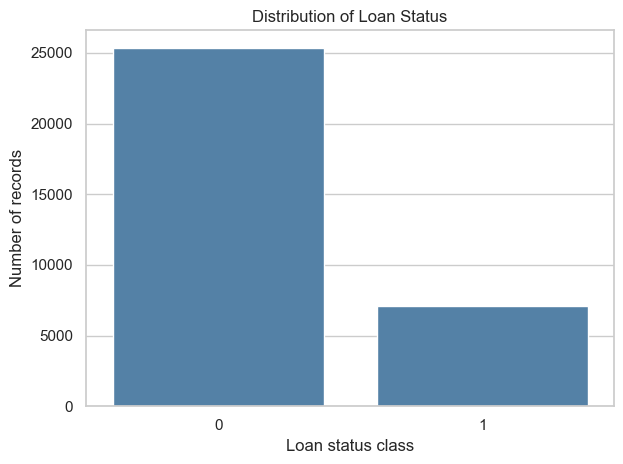

The majority class has 78.1% of all records.
If one class is much larger, compare F1, recall, and ROC-AUC instead of relying on accuracy alone.


In [6]:
# Graph 1: Target distribution
ax = sns.countplot(data=df, x="loan_status", order=[0, 1], color="steelblue")
ax.set(title="Distribution of Loan Status", xlabel="Loan status class", ylabel="Number of records")
plt.tight_layout()
plt.show()

majority_share = class_counts.max() / class_counts.sum()
print(f"The majority class has {majority_share:.1%} of all records.")
print("If one class is much larger, compare F1, recall, and ROC-AUC instead of relying on accuracy alone.")

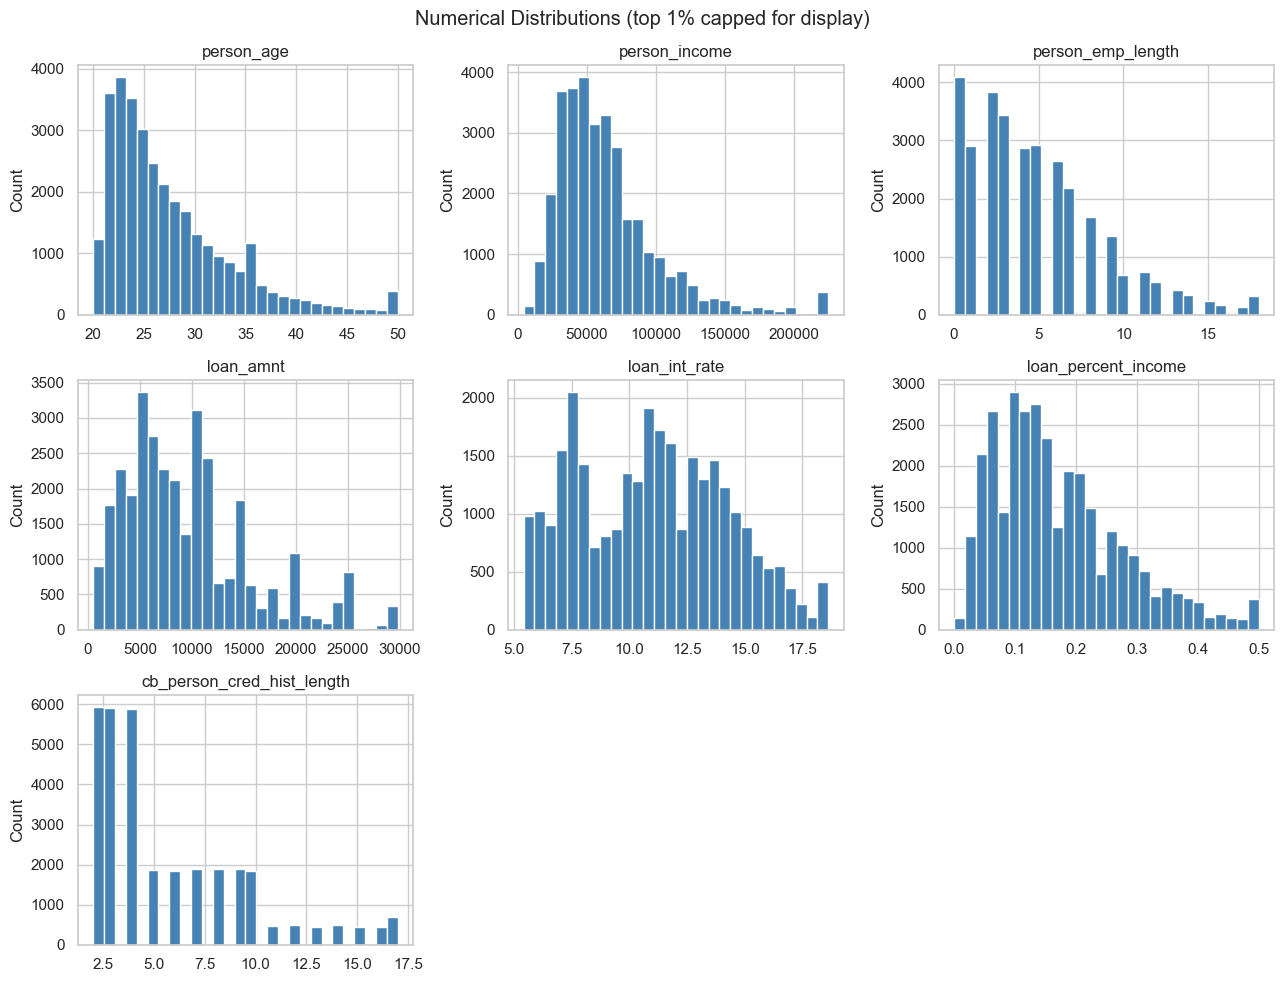

Tall bars show common values. Long tails suggest unusual values or outliers.


In [7]:
# Graph 2: Histograms for all seven numerical predictors
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.ravel(), numeric_columns):
    values = df[col].dropna()
    upper = values.quantile(0.99)
    ax.hist(values.clip(upper=upper), bins=28, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Count")
for ax in axes.ravel()[len(numeric_columns):]:
    ax.axis("off")
plt.suptitle("Numerical Distributions (top 1% capped for display)")
plt.tight_layout()
plt.show()
print("Tall bars show common values. Long tails suggest unusual values or outliers.")

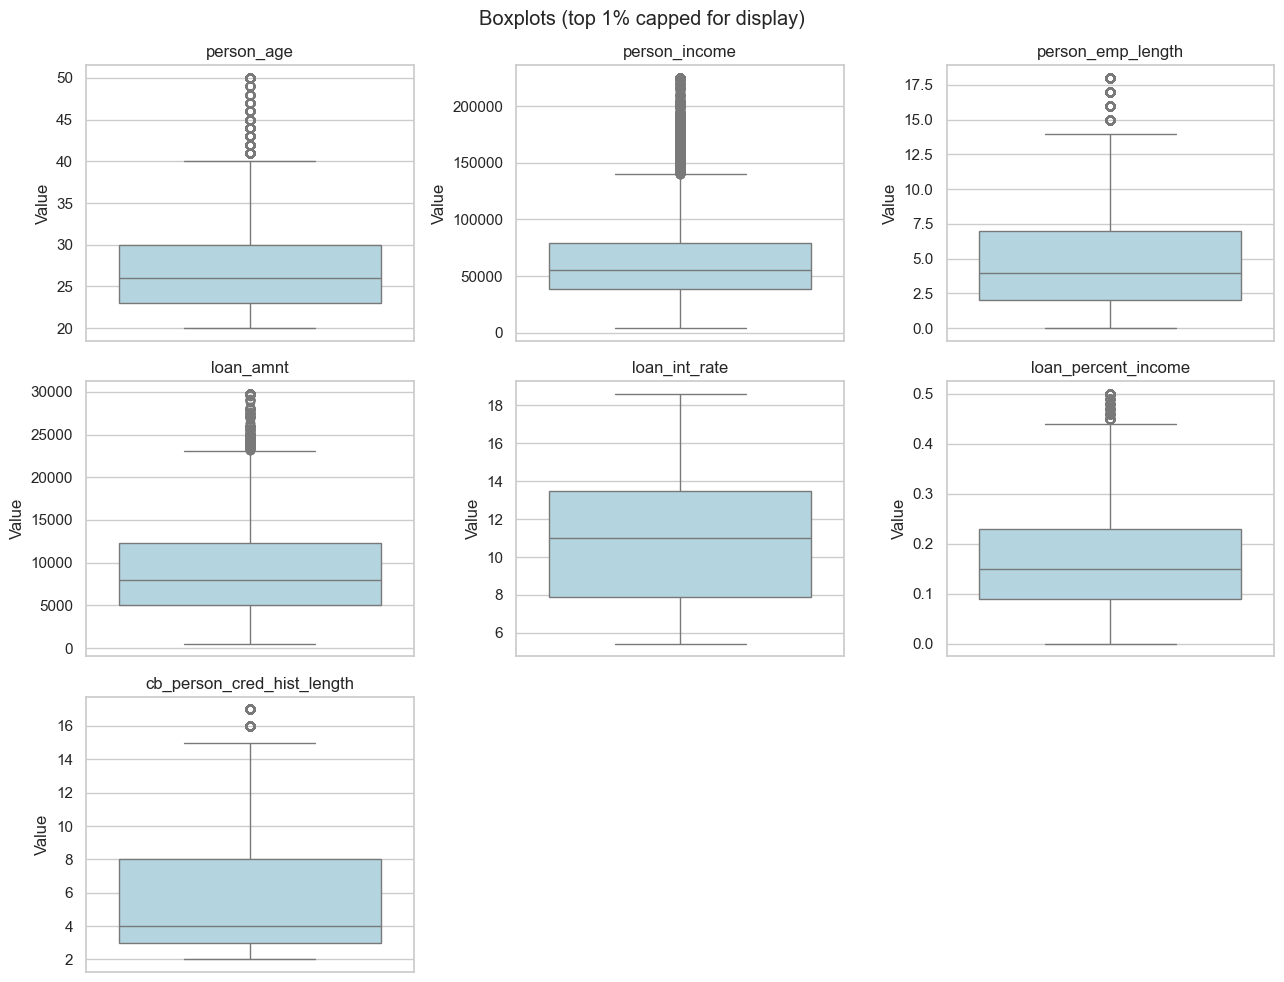

The middle line is the median; dots outside the box may be unusual observations.


In [8]:
# Graph 3: Boxplots for numerical features
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.ravel(), numeric_columns):
    values = df[col].dropna()
    sns.boxplot(y=values.clip(upper=values.quantile(0.99)), ax=ax, color="lightblue")
    ax.set_title(col)
    ax.set_ylabel("Value")
for ax in axes.ravel()[len(numeric_columns):]:
    ax.axis("off")
plt.suptitle("Boxplots (top 1% capped for display)")
plt.tight_layout()
plt.show()
print("The middle line is the median; dots outside the box may be unusual observations.")

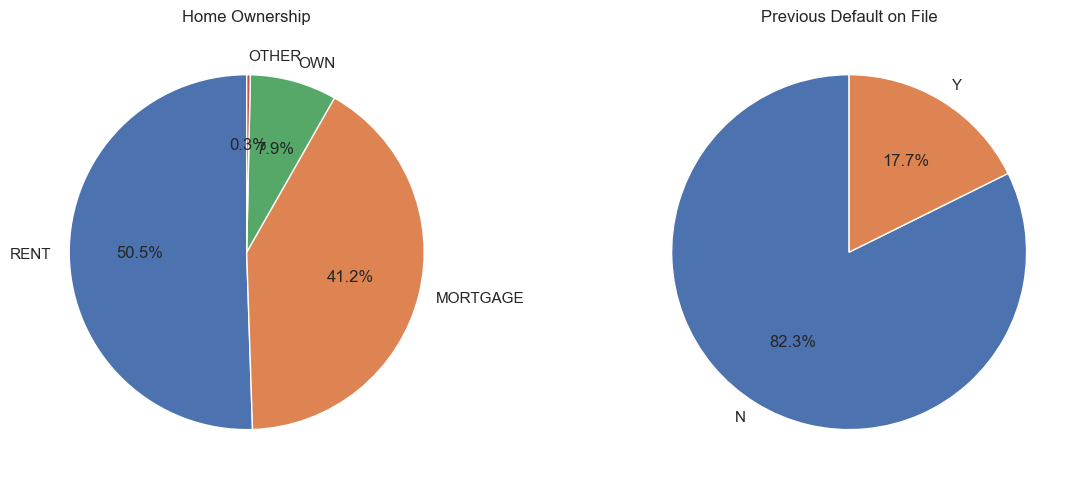

Larger slices mean the category appears more frequently.


In [9]:
# Graph 4: Two pie charts for categorical variables
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in [
    (axes[0], "person_home_ownership", "Home Ownership"),
    (axes[1], "cb_person_default_on_file", "Previous Default on File")
]:
    freq = df[col].fillna("Missing").value_counts()
    ax.pie(freq.values, labels=freq.index, autopct="%.1f%%", startangle=90)
    ax.set_title(title)
plt.tight_layout()
plt.show()
print("Larger slices mean the category appears more frequently.")

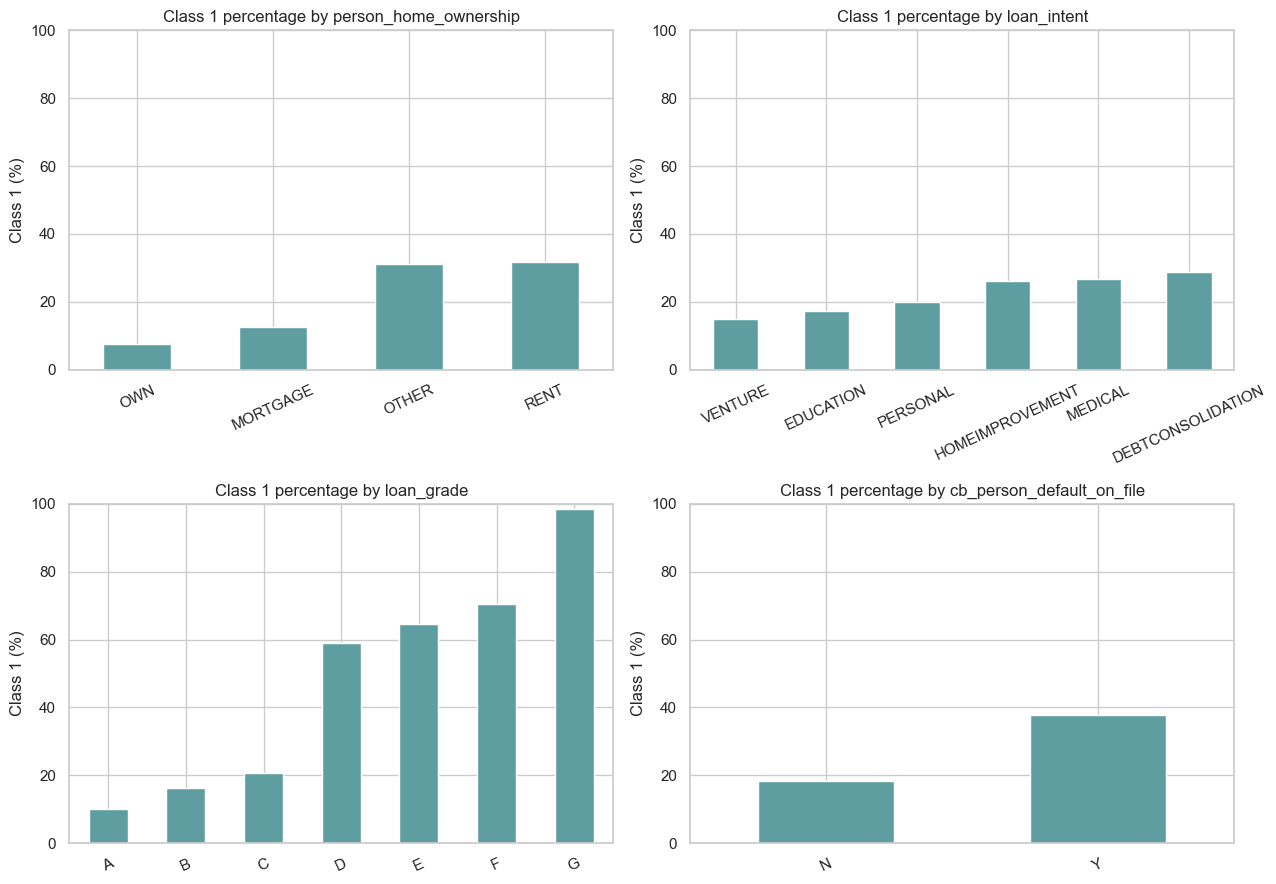

These are group differences, not proof that a particular feature causes the outcome.


In [10]:
# Graph 5: Class 1 percentage by each categorical variable
categorical_columns = [
    "person_home_ownership", "loan_intent",
    "loan_grade", "cb_person_default_on_file"
]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), categorical_columns):
    percentages = (df.groupby(col)["loan_status"].mean() * 100).sort_values()
    percentages.plot(kind="bar", ax=ax, color="cadetblue")
    ax.set_title("Class 1 percentage by " + col)
    ax.set_xlabel("")
    ax.set_ylabel("Class 1 (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print("These are group differences, not proof that a particular feature causes the outcome.")

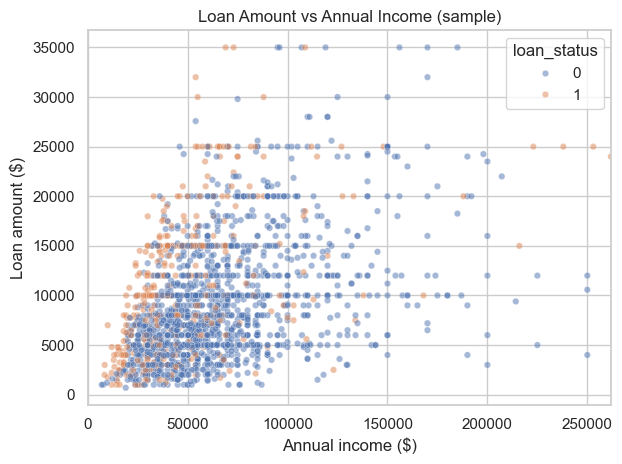

Check whether the two classes occupy different regions or overlap heavily.


In [11]:
# Graph 6: Income compared with requested loan amount
sample = df[["person_income", "loan_amnt", "loan_status"]].dropna()
sample = sample.sample(n=min(1800, len(sample)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="person_income", y="loan_amnt",
                hue="loan_status", alpha=0.5, s=22)
plt.xlim(0, sample["person_income"].quantile(0.99) * 1.1)
plt.title("Loan Amount vs Annual Income (sample)")
plt.xlabel("Annual income ($)")
plt.ylabel("Loan amount ($)")
plt.tight_layout()
plt.show()
print("Check whether the two classes occupy different regions or overlap heavily.")

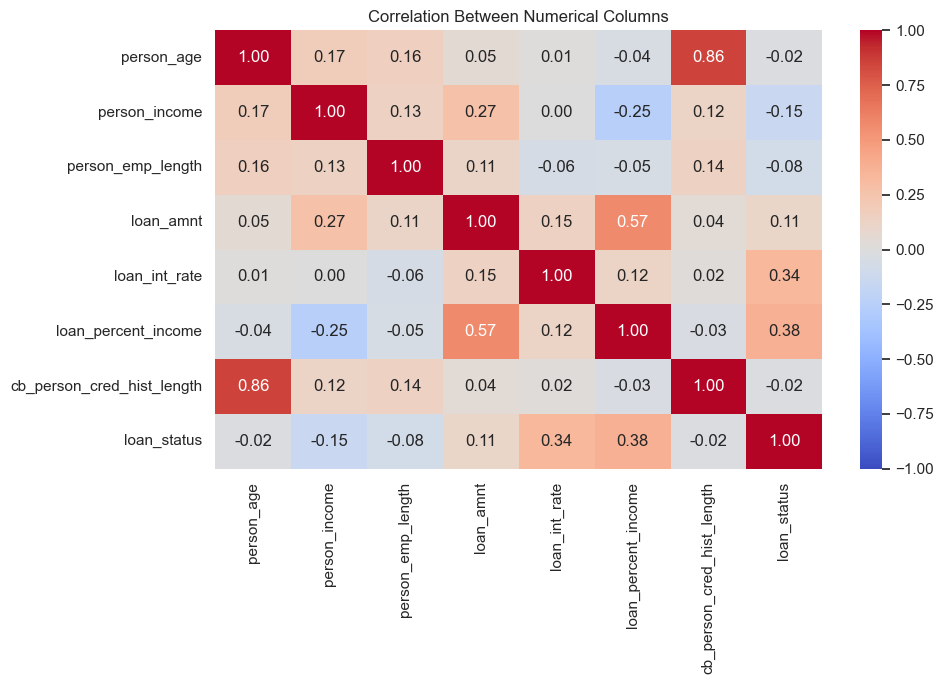

Correlations close to +1 or -1 indicate stronger linear relationships.


In [12]:
# Graph 7: Correlation heatmap for numerical columns and numeric loan_status
corr = df[numeric_columns + ["loan_status"]].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Numerical Columns")
plt.tight_layout()
plt.show()
print("Correlations close to +1 or -1 indicate stronger linear relationships.")

## 6. Split the data before cleaning for the models

We make an **80% training / 20% testing** split, keeping the proportions of Class 0 and Class 1 similar in each split. The test data stays separate until the models are chosen.

**Feature sets:** `All 11 predictors` includes every provided column except `loan_status`; `Early application (9 predictors)` also excludes `loan_grade` and `loan_int_rate`. These might be determined during the lending process, so using them for an earlier-stage prediction could give an unrealistic advantage.

In [13]:
y = df["loan_status"]
all_predictors = [col for col in expected_columns if col != "loan_status"]
early_predictors = [col for col in all_predictors
                    if col not in ["loan_grade", "loan_int_rate"]]

X_all = df[all_predictors]
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

feature_sets = {
    "All 11 predictors": all_predictors,
    "Early application (9 predictors)": early_predictors
}
print("Train rows:", len(X_train_all))
print("Test rows:", len(X_test_all))
for name, columns in feature_sets.items():
    print(f"{name}: {len(columns)} features")

Train rows: 25932
Test rows: 6484
All 11 predictors: 11 features
Early application (9 predictors): 9 features


## 7. Preprocessing and model training

Missing numerical values are filled using the **median**. Missing categories are filled using the **most common category**, and text columns are **one-hot encoded**. Scaling is used for numerical variables. Importantly, these steps happen **inside a pipeline**, so cross-validation does not learn statistics from the validation folds.

We compare a simple majority-class **baseline**, **Logistic Regression**, and **Random Forest** using three-fold stratified cross-validation on training data only.

In [14]:
def make_pipeline(feature_names, model):
    # Find numeric and categorical feature names for this particular setup.
    numerical = [c for c in feature_names if c in numeric_columns]
    categorical = [c for c in feature_names if c not in numeric_columns]

    numeric_pipe = Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])
    category_pipe = Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessing = ColumnTransformer([
        ("numbers", numeric_pipe, numerical),
        ("categories", category_pipe, categorical)
    ])
    return Pipeline([("prepare", preprocessing), ("model", model)])

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=3,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    )
}
print("Ready to compare", len(models), "models across", len(feature_sets), "feature sets.")

Ready to compare 3 models across 2 feature sets.


In [15]:
cross_validation = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE
)
cv_results = []

for setup_name, cols in feature_sets.items():
    for model_name, model in models.items():
        pipeline = make_pipeline(cols, model)
        scores = cross_validate(
            pipeline, X_train_all[cols], y_train, cv=cross_validation,
            scoring={"ROC-AUC": "roc_auc", "F1": "f1"}, n_jobs=1
        )
        cv_results.append({
            "Feature set": setup_name,
            "Model": model_name,
            "CV ROC-AUC": scores["test_ROC-AUC"].mean(),
            "CV F1": scores["test_F1"].mean()
        })
        print("Completed:", setup_name, "/", model_name)

comparison = pd.DataFrame(cv_results).sort_values("CV ROC-AUC", ascending=False)
display(comparison.round(3))

# Pick the overall best combination using cross-validation only.
best_row = comparison.iloc[0]
best_setup = best_row["Feature set"]
best_algorithm = best_row["Model"]
best_columns = feature_sets[best_setup]
print("Selected feature set:", best_setup)
print("Selected algorithm:", best_algorithm)

Completed: All 11 predictors / Baseline
Completed: All 11 predictors / Logistic Regression
Completed: All 11 predictors / Random Forest
Completed: Early application (9 predictors) / Baseline
Completed: Early application (9 predictors) / Logistic Regression
Completed: Early application (9 predictors) / Random Forest


,Feature set,Model,CV ROC-AUC,CV F1
2,All 11 predictors,Random Forest,0.928,0.799
1,All 11 predictors,Logistic Regression,0.871,0.642
5,Early application (9 predictors),Random Forest,0.869,0.671
4,Early application (9 predictors),Logistic Regression,0.807,0.541
0,All 11 predictors,Baseline,0.500,0.000
3,Early application (9 predictors),Baseline,0.500,0.000


Selected feature set: All 11 predictors
Selected algorithm: Random Forest


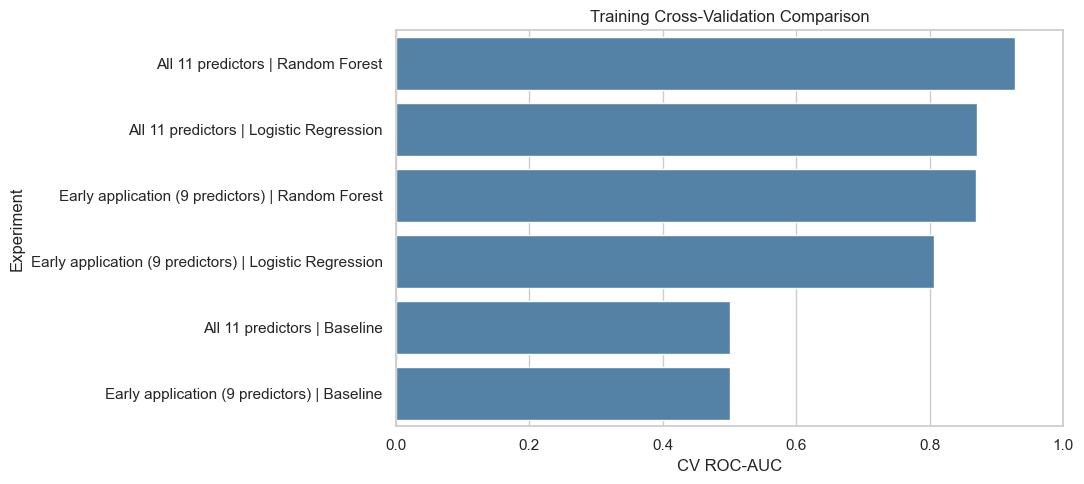

Higher ROC-AUC means better separation of the two target classes.


In [16]:
# Graph 8: Compare average ROC-AUC scores
comparison_plot = comparison.copy()
comparison_plot["Experiment"] = comparison_plot["Feature set"] + " | " + comparison_plot["Model"]
plt.figure(figsize=(11, 5))
sns.barplot(data=comparison_plot, x="CV ROC-AUC", y="Experiment", color="steelblue")
plt.xlim(0, 1)
plt.title("Training Cross-Validation Comparison")
plt.tight_layout()
plt.show()
print("Higher ROC-AUC means better separation of the two target classes.")

## 8. Final test evaluation

Now we fit the chosen model on the **entire training subset** and evaluate it **once** on the untouched test subset. We report accuracy, precision, recall, F1-score, and ROC-AUC. For imbalanced outcomes, F1-score and recall are often more informative than accuracy alone.

In [17]:
best_model = make_pipeline(best_columns, models[best_algorithm])
best_model.fit(X_train_all[best_columns], y_train)

X_test = X_test_all[best_columns]
predicted = best_model.predict(X_test)
prob_class_1 = best_model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, predicted),
    "Precision (Class 1)": precision_score(y_test, predicted, zero_division=0),
    "Recall (Class 1)": recall_score(y_test, predicted, zero_division=0),
    "F1 (Class 1)": f1_score(y_test, predicted, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, prob_class_1)
}
print("Test results for", best_setup, "and", best_algorithm)
display(pd.DataFrame([metrics]).round(3))
print(classification_report(y_test, predicted, target_names=["Class 0", "Class 1"], zero_division=0))

Test results for All 11 predictors and Random Forest


,Accuracy,Precision (Class 1),Recall (Class 1),F1 (Class 1),ROC-AUC
0,0.923,0.889,0.743,0.809,0.926


              precision    recall  f1-score   support

     Class 0       0.93      0.97      0.95      5066
     Class 1       0.89      0.74      0.81      1418

    accuracy                           0.92      6484
   macro avg       0.91      0.86      0.88      6484
weighted avg       0.92      0.92      0.92      6484



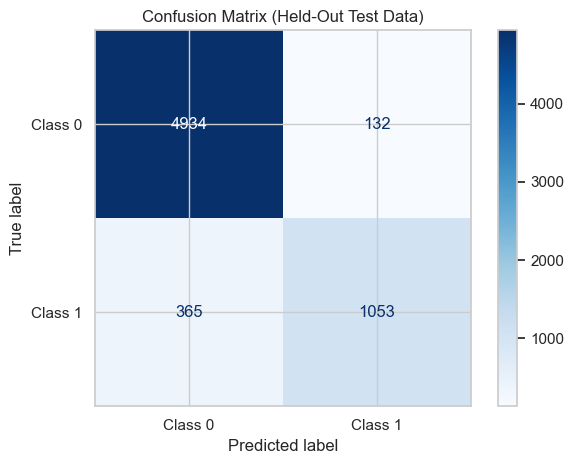

The diagonal counts are correct predictions; other cells are mistakes.


In [18]:
# Graph 9: Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted, display_labels=["Class 0", "Class 1"], cmap="Blues"
)
plt.title("Confusion Matrix (Held-Out Test Data)")
plt.tight_layout()
plt.show()
print("The diagonal counts are correct predictions; other cells are mistakes.")

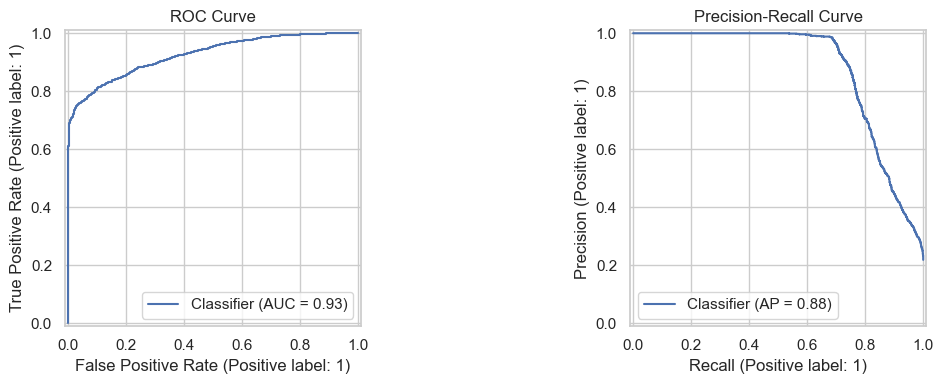

These curves show how performance changes as the prediction threshold changes.


In [19]:
# Graphs 10 and 11: ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, prob_class_1, ax=axes[0])
axes[0].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, prob_class_1, ax=axes[1])
axes[1].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()
print("These curves show how performance changes as the prediction threshold changes.")

## 9. Understand which features are helpful

Permutation importance measures how much the selected model's ROC-AUC falls when one column is randomly shuffled. A larger drop means that column contributed more to the predictions. This is an association, not proof of cause. We use a small sample for speed.

,Feature,Importance
8,loan_percent_income,0.0762
2,person_home_ownership,0.0738
1,person_income,0.0503
5,loan_grade,0.0464
4,loan_intent,0.0331
7,loan_int_rate,0.0176
9,cb_person_default_on_file,0.0070
3,person_emp_length,0.0051
6,loan_amnt,0.0025
0,person_age,0.0010


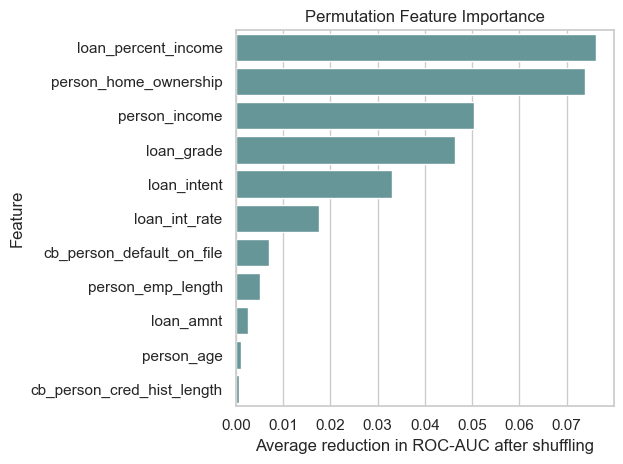

In [20]:
sample_rows = X_test.sample(n=min(1000, len(X_test)), random_state=RANDOM_STATE).index
imp = permutation_importance(
    best_model, X_test.loc[sample_rows], y_test.loc[sample_rows],
    scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE
)
importance = pd.DataFrame({
    "Feature": best_columns,
    "Importance": imp.importances_mean
}).sort_values("Importance", ascending=False)
display(importance.round(4))

# Graph 12: Plot importance results
sns.barplot(data=importance, x="Importance", y="Feature", color="cadetblue")
plt.title("Permutation Feature Importance")
plt.xlabel("Average reduction in ROC-AUC after shuffling")
plt.tight_layout()
plt.show()

## 10. Predict an example applicant

In [21]:
example_applicant = pd.DataFrame([{
    "person_age": 28,
    "person_income": 55000,
    "person_home_ownership": "RENT",
    "person_emp_length": 4,
    "loan_intent": "PERSONAL",
    "loan_grade": "B",
    "loan_amnt": 10000,
    "loan_int_rate": 11.5,
    "loan_percent_income": 10000 / 55000,
    "cb_person_default_on_file": "N",
    "cb_person_cred_hist_length": 5
}])

example_input = example_applicant[best_columns]
example_label = best_model.predict(example_input)[0]
example_probability = best_model.predict_proba(example_input)[0, 1]
print("Predicted class:", example_label)
print(f"Predicted probability of Class 1: {example_probability:.1%}")
print("Check the source documentation before interpreting Class 1 as approval or default.")

Predicted class: 0
Predicted probability of Class 1: 22.7%
Check the source documentation before interpreting Class 1 as approval or default.
